# CSIS 604 Team Project — Raft Simulation

**Project:** Empirical Analysis of Raft Consensus under Network Stress

**Team Members:**
- Christian Soto
- Dan Johnson

**Course:** CSIS 604 — Distributed Systems

---



## Exercise 1 — Latency Spikes & Split-Brain Elections

### Network Latency vs. Election Frequency

#### Methodology Synthesis

To find the *precise* latency threshold that induces continuous candidate re-elections and leadership instability, it is necessary to find an observable metric via the Consul HTTP API. A naive approach involves polling the `/v1/status/leader` endpoint and noting whenever there is a change in the reported leader. However, this methodology comes with a few caveats that limit its effectiveness for tracking election events:

1. One or more election events can occur between polling attempts, reducing the signal-to-noise ratio of a leader-change count.
2. An election can result in the same node regaining leadership, leaving the leader address unchanged despite an election taking place.

Tuning the sampling interval helps mitigate (1), while (2)—along with cases where latency prevents a candidate from winning or holding quorum—motivates a stronger metric. When a cluster has no active leader, `/v1/status/leader` returns an empty value (`""`), indicating an election or leader-unavailability window at that sample timestamp.

To capture sustained instability rather than isolated swaps, we can frame leaderlessness in terms of *duty cycle*. In circuit analysis, duty cycle is the proportion of a period spent in an active state versus `0 V`. Analogously, for a leaderless duty cycle $d$ with $0 \le d \le 1$, $d$ represents the fraction of samples within an observation window where no leader is present—rising from $0$ in a stable cluster to a transition band and saturating near $1.0$ when the cluster cannot maintain leadership.

#### Guided Experiment

Run the cells below to replicate the expirement.  Note that the `docker compose` cell must be given enough time to run before moving on to the next steps

In [ ]:
# Docker Compose command to start the services defined in the docker-compose.yml file in detached mode.
# Note that we use the --wait flag to ensure that the command waits for the services!sudo docker ps to be fully started prior
# to returning control to the shell. This is useful in scenarios where subsequent commands depend on the services
# being fully operational.

!sudo docker compose -f docker-compose.yml up -d --wait

In [14]:
# Check to make sure the services are running
! sudo docker ps --format '{{{{.Names}}}} {{{{.Status}}}} --> {{{{.Ports}}}}' | grep -E 'consul([1-3]|-ui)|toxiproxy[1-3]'

Place your finger on the fingerprint reader
consul-ui Up 12 minutes --> 0.0.0.0:8500->8500/tcp, [::]:8500->8500/tcp, 8300-8302/tcp, 8301-8302/udp, 0.0.0.0:8600->8600/tcp, [::]:8600->8600/tcp, 0.0.0.0:8600->8600/udp, [::]:8600->8600/udp
toxiproxy3 Up 12 minutes --> 0.0.0.0:8476->8474/tcp, [::]:8476->8474/tcp
toxiproxy2 Up 12 minutes --> 0.0.0.0:8475->8474/tcp, [::]:8475->8474/tcp
toxiproxy1 Up 12 minutes --> 0.0.0.0:8474->8474/tcp, [::]:8474->8474/tcp
consul3-node Up 12 minutes --> 8300-8302/tcp, 8500/tcp, 8301-8302/udp, 8600/tcp, 8600/udp
consul2-node Up 12 minutes --> 8300-8302/tcp, 8500/tcp, 8301-8302/udp, 8600/tcp, 8600/udp
consul1-node Up 12 minutes --> 8300-8302/tcp, 8500/tcp, 8301-8302/udp, 8600/tcp, 8600/udp


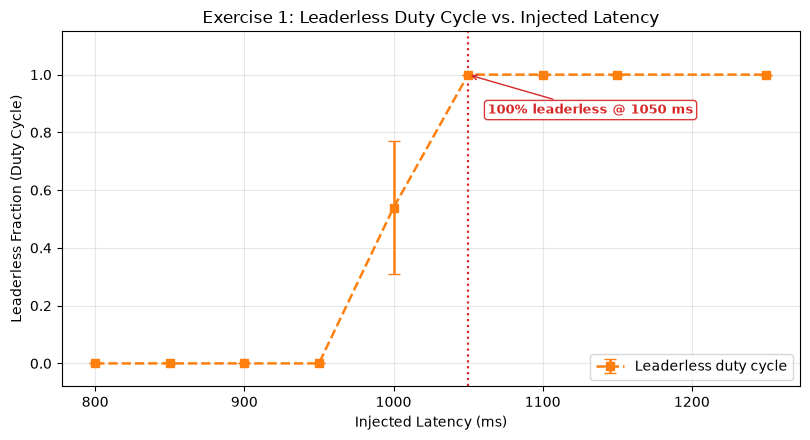

In [15]:
import time
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Constants
LEADER_URL = "http://localhost:8500/v1/status/leader"
PROXIES = [
    ("http://localhost:8474", "consul1"),
    ("http://localhost:8475", "consul2"),
    ("http://localhost:8476", "consul3"),
]
TOXIC_NAME = "ex1_latency"


def set_latency_all(
    session: requests.Session, lat_ms: int, jitter_ms: int = 25
) -> None:
  """
  Set latency toxic on all proxies. Bookend this method with clear_latency_all() 
  to ensure a clean state before and after the test.
  """
  payload = {
      "name": TOXIC_NAME,
      "type": "latency",
      "attributes": {"latency": int(lat_ms), "jitter": int(jitter_ms)},
  }
  for base_url, proxy_name in PROXIES:
    resp = session.post(
        f"{base_url}/proxies/{proxy_name}/toxics",
        json=payload,
        timeout=3.0,
    )
    if resp.status_code == 409:
      session.delete(
          f"{base_url}/proxies/{proxy_name}/toxics/{TOXIC_NAME}", timeout=3.0
      )
      resp = session.post(
          f"{base_url}/proxies/{proxy_name}/toxics",
          json=payload,
          timeout=3.0,
      )
    resp.raise_for_status()


def clear_latency_all(session: requests.Session) -> None:
  """
  Clear latency toxic on all proxies. Bookend this method with set_latency_all()
  to ensure a clean state before and after the test.
  """
  for base_url, proxy_name in PROXIES:
    try:
      session.delete(
          f"{base_url}/proxies/{proxy_name}/toxics/{TOXIC_NAME}",
          timeout=3.0,
      )
    except requests.RequestException:
      pass


def measure_leaderless_duty_cycle(
    session: requests.Session,
    window_s: float = 12.0,
    interval_s: float = 0.2,
    timeout: float = 1.0,
) -> dict:
  """
  Measure the fraction of time the cluster is leaderless over a given window.
  Output is a dictionary with the following shape:
  {
      "elapsed_s": float,  # Total elapsed time in seconds}
      "n_samples": int,  # Total number of samples taken
      "leaderless_ratio": float,  # Fraction of samples where no leader was found
  }
  """
  leaderless_samples = 0
  total_samples = 0
  t0 = time.monotonic()
  deadline = t0 + window_s

  while time.monotonic() < deadline:
    leader = ""
    try:
      r = session.get(LEADER_URL, timeout=timeout)
      if r.ok:
        leader = r.text.strip().strip('"')
    except requests.RequestException:
      leader = ""

    total_samples += 1
    if not leader:
      leaderless_samples += 1

    rem = deadline - time.monotonic()
    if rem > 0:
      time.sleep(min(interval_s, rem))

  elapsed = max(time.monotonic() - t0, 1e-6)
  return {
      "elapsed_s": elapsed,
      "n_samples": total_samples,
      "leaderless_ratio": leaderless_samples / max(total_samples, 1),
  }


def run_precision_duty_cycle(
    latencies_ms: list[int],
    reps: int = 3,
    window_s: float = 12.0,
    interval_s: float = 0.2,
    jitter_ms: int = 25,
    settle_s: float = 2.0,
    csv_path: str = "ex1_leaderless_duty_cycle.csv",
    plot_path: str = "ex1_leaderless_duty_cycle.png",
) -> pd.DataFrame:
  """
  Run a precision duty cycle experiment by injecting latency into the cluster and
  measuring the fraction of time the cluster is leaderless. The results are saved
  to a CSV file and a plot is generated. The function returns a DataFrame containing
  the raw results of the experiment. 
  """
  rows: list[dict] = []
  with requests.Session() as session:
    clear_latency_all(session)
    try:
      for lat in latencies_ms:
        for rep in range(reps):
          if lat > 0:
            set_latency_all(session, lat_ms=lat, jitter_ms=jitter_ms)
          try:
            stats = measure_leaderless_duty_cycle(
                session, window_s=window_s, interval_s=interval_s
            )
            rows.append({
                "latency_ms": lat,
                "jitter_ms": jitter_ms if lat > 0 else 0,
                "rep": rep,
                **stats,
            })
          finally:
            if lat > 0:
              clear_latency_all(session)
          if settle_s > 0:
            time.sleep(settle_s)
    finally:
      clear_latency_all(session)

  df = pd.DataFrame(rows)
  df.to_csv(csv_path, index=False)

  summary = (
      df.groupby("latency_ms", as_index=False)
      .agg(
          mean_leaderless=("leaderless_ratio", "mean"),
          std_leaderless=("leaderless_ratio", "std"),
      )
      .fillna({"std_leaderless": 0.0})
  )

  fig, ax = plt.subplots(figsize=(8.2, 4.5))
  ax.errorbar(
      summary["latency_ms"],
      summary["mean_leaderless"],
      yerr=summary["std_leaderless"],
      marker="s",
      linestyle="--",
      capsize=4,
      color="tab:orange",
      linewidth=1.8,
      label="Leaderless duty cycle",
  )

  ax.set_title("Exercise 1: Leaderless Duty Cycle vs. Injected Latency")
  ax.set_xlabel("Injected Latency (ms)")
  ax.set_ylabel("Leaderless Fraction (Duty Cycle)")
  ax.set_ylim(-0.08, 1.15)
  ax.grid(True, alpha=0.3)

  sat_rows = summary[summary["mean_leaderless"] >= 0.99]
  if not sat_rows.empty:
    sat_lat = sat_rows.iloc[0]["latency_ms"]
    sat_val = sat_rows.iloc[0]["mean_leaderless"]
    ax.axvline(sat_lat, color="tab:red", linestyle=":", linewidth=1.6)
    ax.annotate(
        f"100% leaderless @ {sat_lat:g} ms",
        xy=(sat_lat, sat_val),
        xytext=(14, -28),
        textcoords="offset points",
        arrowprops=dict(arrowstyle="->", color="tab:red"),
        fontsize=9,
        fontweight="bold",
        color="tab:red",
        bbox=dict(
            boxstyle="round,pad=0.25",
            fc="white",
            ec="tab:red",
            alpha=0.92,
        ),
    )

  ax.legend(loc="lower right")
  fig.tight_layout()
  plt.savefig(plot_path, dpi=150)
  plt.show()

  return df


precision_latencies = [800, 850, 900, 950, 1000, 1050, 1100, 1150, 1250]
df_ex1 = run_precision_duty_cycle(
    precision_latencies,
    reps=3,
    window_s=12.0,
    interval_s=0.2,
    jitter_ms=25,
    settle_s=2.0,
)

In [17]:
!sudo docker compose -f docker-compose.yml down


Place your finger on the fingerprint reader
]3008;start=2f1eee5a0bcd4088a94c07ff04e5a42c;user=PowersOfEight;hostname=penseur;machineid=1d0e8edff6724421a75e0c37dc32f447;bootid=ed952c49bf2d4d7cac330b11cb20aa37;pid=22019;pidfdid=31376;comm=sudo;targetuser=root;type=session\[+] down 0/4
 ⠋ Container toxiproxy2 Stopping                                            0.0s
 ⠋ Container toxiproxy3 Stopping                                            0.0s
 ⠋ Container consul-ui  Stopping                                            0.0s
 ⠋ Container toxiproxy1 Stopping                                            0.0s

 ⠙ Container toxiproxy2 Stopping                                            0.1s
 ⠙ Container toxiproxy3 Stopping                                            0.1s
 ⠙ Container consul-ui  Stopping                                            0.1s
 ⠙ Container toxiproxy1 Stopping                                            0.1s

 ⠹ Container toxiproxy2 Stopping                                

### Exercise 1 — Analysis

#### Conclusions

Based on the data collected from the experiment on local hardware, at 1050 milliseconds of latency, elections become continuous in the test jig.  However, this could be somewhat dependent on hardware, test jig configurations, and by varying other factors such as the physical nodes themselves.

---

## Exercise 2 — Minority Partition & Uncommitted Log Tracing

#### Methodology Synthesis

To examine how Raft handles a network partition, we divided a five-node Consul cluster into a three-node majority and a two-node minority. Since Raft requires a majority of nodes to commit log entries, this configuration allows us to observe how the cluster behaves when some nodes can no longer communicate with the elected leader.

Before introducing the partition, we recorded each node's Raft state, current term, and log indexes using `consul info`. We then used `iptables` to block communication between the two groups in both directions. This allowed the nodes within each partition to communicate while preventing communication between the majority and minority.

Once the partition was established, we attempted key-value writes from both groups to compare their ability to process requests. We also examined the Raft configuration to identify the active leader and observe changes in the cluster's state.

Finally, we removed the firewall rules to restore communication between all five nodes. We checked the Raft configuration and retrieved the attempted writes to determine whether the nodes had synchronized. These measurements provided the information needed to construct the Log Lifecycle Trace Table and explain how Raft maintained consistency during the partition and recovery.

In [ ]:
%%bash
echo "Running script, note you may need to escalate privileges..."
sudo bash << 'EOF'
echo "Spinning up the cluster as $USER..."

sudo docker compose -f expanded-docker-compose.yml up -d --wait

echo "Waiting for all services to be up...."

echo "Verifying depdendencies...."

for service in $(yq '.services | keys[]' expanded-docker-compose.yml | tr -d '"'); do

    if [[ $(docker ps --filter name="${service}" --format '{{.Names}}' | wc -l) -eq 0 ]] ; then
        echo "ERROR: did not find dependent cluster service named '${service}'."
        echo "Please run 'sudo docker compose -f expanded-docker-compose.yml down' and re-run the cell."
        exit 1
    fi

done

echo "All dependencies verified!  Proceed to the next cell."

exit 0
EOF

bash: line 1: Running script, note you may need to escalate privileges...: command not found


Spinning up the cluster as root...


 Network raft_raft-net Creating 
 Network raft_raft-net Created 
 Container consul5-node Creating 
 Container consul2-node Creating 
 Container consul4-node Creating 
 Container consul1-node Creating 
 Container consul3-node Creating 
 Container consul3-node Created 
 Container toxiproxy3 Creating 
 Container consul5-node Created 
 Container toxiproxy5 Creating 
 Container consul4-node Created 
 Container toxiproxy4 Creating 
 Container consul2-node Created 
 Container toxiproxy2 Creating 
 Container consul1-node Created 
 Container toxiproxy1 Creating 
 Container consul-ui Creating 
 Container toxiproxy3 Created 
 Container raft-udp-lan-3-1 Creating 
 Container raft-udp-wan-3-1 Creating 
 Container toxiproxy4 Created 
 Container raft-udp-lan-4-1 Creating 
 Container raft-udp-wan-4-1 Creating 
 Container toxiproxy5 Created 
 Container raft-udp-wan-5-1 Creating 
 Container raft-udp-lan-5-1 Creating 
 Container toxiproxy2 Created 
 Container raft-udp-lan-2-1 Creating 
 Container raft-udp

Waiting for all services to be up....
Verifying depdendencies....
All dependencies verified!  Proceed to the next cell.
Place your finger on the fingerprint reader


        phase       side          leader  write_ok reconciled_value
   1_baseline majority_3 10.99.0.11:8300         1               ok
2_partitioned majority_3 10.99.0.11:8300         0                 
     3_healed majority_3 10.99.0.11:8300         1   committed_3of5


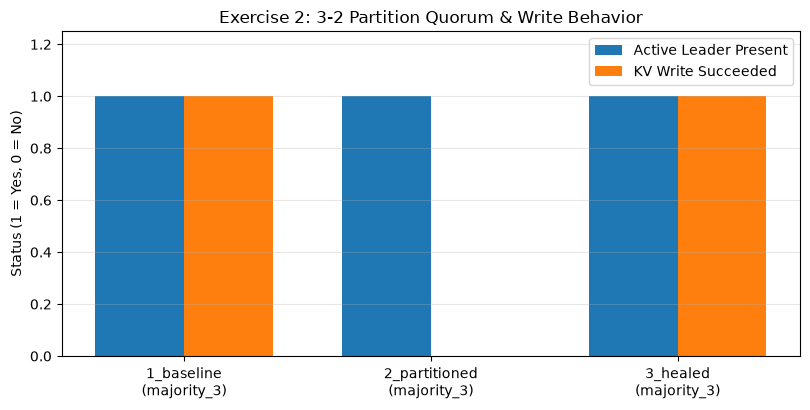

In [47]:
import time
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Host HTTP API ports exposed on consul1-node..consul5-node / consul-ui
NODE_HTTP_APIS = {
    1: "http://localhost:8500",  # override per node if exposed separately, or query via docker exec
}
TOXIPROXY_APIS = {
    1: "http://localhost:8474",
    2: "http://localhost:8475",
    3: "http://localhost:8476",
    4: "http://localhost:8477",
    5: "http://localhost:8478",
}
PROXY_SUFFIXES = ["", "-serf", "-wan"]
PARTITION_TOXIC_NAME = "ex2_partition_timeout"

MAJORITY_NODES = [1, 3, 4]  # 3/5 quorum retained
MINORITY_NODES = [2, 5]  # 2/5 lacks quorum


def set_nodes_isolated(
    session: requests.Session, node_ids: list[int], isolated: bool
) -> None:
  for nid in node_ids:
    api = TOXIPROXY_APIS[nid]
    for suffix in PROXY_SUFFIXES:
      proxy_name = f"consul{nid}{suffix}"
      try:
        session.delete(
            f"{api}/proxies/{proxy_name}/toxics/{PARTITION_TOXIC_NAME}",
            timeout=3.0,
        )
      except requests.RequestException:
        pass

      if isolated:
        payload = {
            "name": PARTITION_TOXIC_NAME,
            "type": "timeout",
            "stream": "downstream",
            "toxicity": 1.0,
            "attributes": {"timeout": 1},
        }
        resp = session.post(
            f"{api}/proxies/{proxy_name}/toxics",
            json=payload,
            timeout=3.0,
        )
        resp.raise_for_status()


def get_leader(session: requests.Session, base_url: str) -> str:
  try:
    r = session.get(f"{base_url}/v1/status/leader", timeout=1.5)
    if r.ok:
      return r.text.strip().strip('"')
  except requests.RequestException:
    pass
  return ""


def kv_put(
    session: requests.Session, base_url: str, key: str, value: str
) -> tuple[bool, str]:
  try:
    r = session.put(
        f"{base_url}/v1/kv/{key}", data=value.encode("utf-8"), timeout=2.5
    )
    return r.ok and r.text.strip() == "true", f"HTTP {r.status_code}: {r.text.strip()}"
  except requests.RequestException as exc:
    return False, f"ERR: {type(exc).__name__}"


def kv_get(session: requests.Session, base_url: str, key: str) -> str | None:
  try:
    r = session.get(f"{base_url}/v1/kv/{key}", params={"raw": "true"}, timeout=2.5)
    if r.status_code == 200:
      return r.text
  except requests.RequestException:
    pass
  return None


def run_exercise_2(
    majority_api: str = "http://localhost:8500",
    minority_api: str | None = None,
    settle_s: float = 4.0,
    csv_path: str = "ex2_partition_reconciliation.csv",
    plot_path: str = "ex2_partition_quorum.png",
) -> pd.DataFrame:
  """
    Runs a 3-2 partition test using Toxiproxy on minority sidecars (2, 5).
    If `minority_api` is None, minority write/leader checks are skipped or
    can be pointed at a minority-side HTTP port if exposed in your Compose YAML.
    """
  records: list[dict] = []

  with requests.Session() as session:
    set_nodes_isolated(session, MINORITY_NODES, isolated=False)
    try:
      # 1. Baseline healthy check
      base_leader = get_leader(session, majority_api)
      ok_base, _ = kv_put(session, majority_api, "ex2/baseline", "ok")
      records.append({
          "phase": "1_baseline",
          "side": "majority_3",
          "leader": base_leader,
          "write_ok": int(ok_base),
          "reconciled_value": kv_get(session, majority_api, "ex2/baseline") or "",
      })

      # 2. Apply 3-2 partition (isolate minority nodes 2 and 5)
      set_nodes_isolated(session, MINORITY_NODES, isolated=True)
      time.sleep(settle_s)

      maj_leader = get_leader(session, majority_api)
      ok_maj, _ = kv_put(session, majority_api, "ex2/majority_write", "committed_3of5")
      records.append({
          "phase": "2_partitioned",
          "side": "majority_3",
          "leader": maj_leader,
          "write_ok": int(ok_maj),
          "reconciled_value": kv_get(session, majority_api, "ex2/majority_write") or "",
      })

      if minority_api:
        min_leader = get_leader(session, minority_api)
        ok_min, _ = kv_put(session, minority_api, "ex2/minority_write", "uncommitted_2of5")
        records.append({
            "phase": "2_partitioned",
            "side": "minority_2",
            "leader": min_leader,
            "write_ok": int(ok_min),
            "reconciled_value": kv_get(session, minority_api, "ex2/minority_write") or "",
        })

      # 3. Heal partition and allow Raft log/state reconciliation
      set_nodes_isolated(session, MINORITY_NODES, isolated=False)
      time.sleep(settle_s)

      healed_leader = get_leader(session, majority_api)
      maj_val = kv_get(session, majority_api, "ex2/majority_write") or ""
      min_val = kv_get(session, minority_api, "ex2/majority_write") if minority_api else maj_val
      records.append({
          "phase": "3_healed",
          "side": "majority_3",
          "leader": healed_leader,
          "write_ok": 1,
          "reconciled_value": maj_val or "",
      })
      if minority_api:
        records.append({
            "phase": "3_healed",
            "side": "minority_2",
            "leader": get_leader(session, minority_api),
            "write_ok": 1,
            "reconciled_value": min_val or "",
        })
    finally:
      set_nodes_isolated(session, MINORITY_NODES, isolated=False)

  df = pd.DataFrame(records)
  df.to_csv(csv_path, index=False)
  print(df.to_string(index=False))

  # Summary plot for PDF / notebook readability
  fig, ax = plt.subplots(figsize=(8.2, 4.2))
  labels = [f"{r['phase']}\n({r['side']})" for _, r in df.iterrows()]
  has_leader = [1 if r["leader"] else 0 for _, r in df.iterrows()]
  writes = df["write_ok"].tolist()

  x = range(len(labels))
  width = 0.36
  ax.bar([i - width / 2 for i in x], has_leader, width=width, label="Active Leader Present")
  ax.bar([i + width / 2 for i in x], writes, width=width, label="KV Write Succeeded")

  ax.set_xticks(list(x))
  ax.set_xticklabels(labels)
  ax.set_ylim(0, 1.25)
  ax.set_ylabel("Status (1 = Yes, 0 = No)")
  ax.set_title("Exercise 2: 3-2 Partition Quorum & Write Behavior")
  ax.grid(True, axis="y", alpha=0.3)
  ax.legend(loc="upper right")
  fig.tight_layout()
  plt.savefig(plot_path, dpi=150)
  plt.show()

  return df


df_ex2 = run_exercise_2(settle_s=4.0)

In [48]:
%%bash
sudo docker compose -f expanded-docker-compose.yml down

Failed to match fingerprint
 Container raft-udp-lan-1-1 Stopping 
 Container raft-udp-lan-5-1 Stopping 
 Container raft-udp-lan-4-1 Stopping 
 Container raft-udp-wan-1-1 Stopping 
 Container consul-ui Stopping 
 Container raft-udp-lan-2-1 Stopping 
 Container raft-udp-wan-2-1 Stopping 
 Container raft-udp-wan-4-1 Stopping 
 Container raft-udp-wan-3-1 Stopping 
 Container raft-udp-lan-3-1 Stopping 
 Container raft-udp-wan-5-1 Stopping 
 Container raft-udp-lan-2-1 Stopped 
 Container raft-udp-lan-2-1 Removing 
 Container raft-udp-lan-4-1 Stopped 
 Container raft-udp-lan-4-1 Removing 
 Container raft-udp-lan-1-1 Stopped 
 Container raft-udp-lan-1-1 Removing 
 Container raft-udp-wan-2-1 Stopped 
 Container raft-udp-wan-2-1 Removing 
 Container raft-udp-wan-4-1 Stopped 
 Container raft-udp-wan-4-1 Removing 
 Container raft-udp-wan-1-1 Stopped 
 Container raft-udp-wan-1-1 Removing 
 Container raft-udp-wan-5-1 Stopped 
 Container raft-udp-wan-5-1 Removing 
 Container raft-udp-wan-3-1 Stopped 

Place your finger on the fingerprint reader
Place your finger on the fingerprint reader


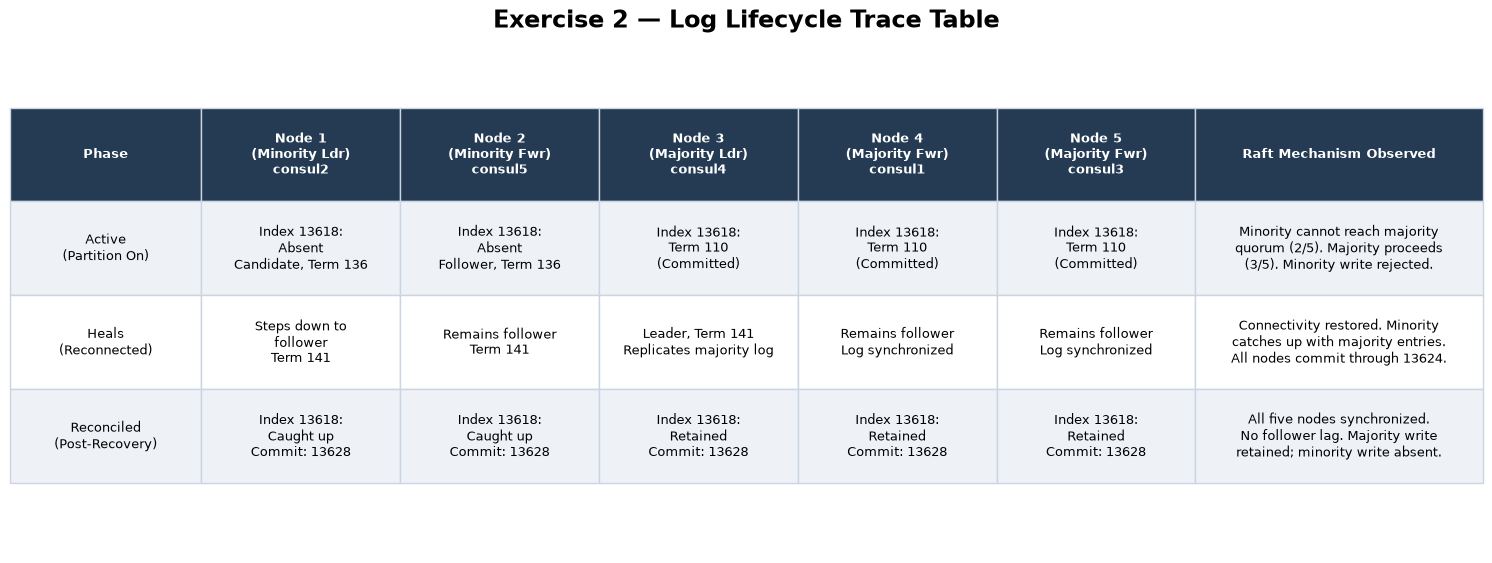

In [4]:
import matplotlib.pyplot as plt

columns = [
    "Phase",
    "Node 1\n(Minority Ldr)\nconsul2",
    "Node 2\n(Minority Fwr)\nconsul5",
    "Node 3\n(Majority Ldr)\nconsul4",
    "Node 4\n(Majority Fwr)\nconsul1",
    "Node 5\n(Majority Fwr)\nconsul3",
    "Raft Mechanism Observed"
]

rows = [
    [
        "Active\n(Partition On)",
        "Index 13618:\nAbsent\nCandidate, Term 136",
        "Index 13618:\nAbsent\nFollower, Term 136",
        "Index 13618:\nTerm 110\n(Committed)",
        "Index 13618:\nTerm 110\n(Committed)",
        "Index 13618:\nTerm 110\n(Committed)",
        "Minority cannot reach majority\n"
        "quorum (2/5). Majority proceeds\n"
        "(3/5). Minority write rejected."
    ],
    [
        "Heals\n(Reconnected)",
        "Steps down to\nfollower\nTerm 141",
        "Remains follower\nTerm 141",
        "Leader, Term 141\nReplicates majority log",
        "Remains follower\nLog synchronized",
        "Remains follower\nLog synchronized",
        "Connectivity restored. Minority\n"
        "catches up with majority entries.\n"
        "All nodes commit through 13624."
    ],
    [
        "Reconciled\n(Post-Recovery)",
        "Index 13618:\nCaught up\nCommit: 13628",
        "Index 13618:\nCaught up\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "All five nodes synchronized.\n"
        "No follower lag. Majority write\n"
        "retained; minority write absent."
    ]
]

fig, ax = plt.subplots(figsize=(19, 6.5))
ax.axis("off")

ax.set_title(
    "Exercise 2 — Log Lifecycle Trace Table",
    fontsize=17, fontweight="bold", pad=18
)

table = ax.table(
    cellText=rows,
    colLabels=columns,
    colWidths=[0.13, 0.135, 0.135, 0.135, 0.135, 0.135, 0.195],
    cellLoc="center",
    loc="center",
    bbox=[0, 0.14, 1, 0.75]
)

table.auto_set_font_size(False)
table.set_fontsize(9)

for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("#CBD5E1")
    if r == 0:
        cell.set_facecolor("#243B53")
        cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor("#EEF2F7" if r % 2 else "white")
        cell.set_text_props(va="center")

plt.show()

### Exercise 2 — Analysis

The five-node Consul cluster was divided into a three-node majority (`consul1`, `consul3`, and `consul4`) and a two-node minority (`consul2` and `consul5`). The partition separated the original leader, `consul2`, from the majority. KV writes were attempted on both sides to observe how Raft handles the loss of a majority quorum.

**Active (Partition On):** The majority elected `consul4` as its new leader and committed entries through log index 13618 with term 110. The minority remained at index 13586 with its last log term at 107. `consul2` entered candidate state because it could no longer maintain leadership without a majority quorum. The majority write succeeded while the minority write returned "No cluster leader."

**Heals (Reconnected):** Network communication was restored and the minority nodes rejoined the cluster as followers. All five nodes reached log and commit index 13624 with term 141. This showed that the minority had caught up with the entries committed by the majority during the partition.

**Reconciled (Post-Recovery):** All five nodes eventually reached commit index 13628 with no replication lag. `consul2` regained leadership and the majority write remained available. The minority write was not committed.

Log index 13618 was used to trace the difference between the two groups. The majority committed this entry while the minority was unable to make progress. Raft synchronized the logs after connectivity was restored. The experiment demonstrated log recovery through replication rather than the replacement of a conflicting uncommitted entry, which was not observed.

---

## Exercise 3 — Packet Loss & Throughput Degradation

#### Methodology Synthesis

To measure the effect of packet loss on write performance, we introduced three packet loss levels of 5%, 10%, and 25% into the Consul cluster using `tc netem`. The purpose was to compare how increasing packet loss affected typical write latency and the slowest successful requests.

A Python script was used to submit key-value writes through the Consul HTTP API at a target rate of 50 writes per second. Each trial lasted 20 seconds, producing 1,000 attempted writes. We performed three trials at each packet loss level to collect multiple measurements under the same network conditions.

The script measured the response time of each request and recorded whether the write succeeded or failed. Successful requests were used to calculate two latency percentiles:

1. **p50:** The median latency, representing the response time at or below which 50% of successful writes completed.
2. **p99:** The 99th-percentile latency, representing the response time at or below which approximately 99% of successful writes completed.

Failed requests and timeouts were recorded separately rather than included in the latency percentiles. This distinction prevents unsuccessful requests from being treated as completed writes.

After completing the trials, we averaged the individual trial percentiles for each packet loss level. The resulting p50 and p99 values were plotted against packet loss to compare typical response times with tail latency. This provided a basis for examining how packet loss affects write performance and why the slowest requests may experience greater delays.

In [ ]:
%%bash
sudo bash << 'EOF'
docker compose -f expanded-docker-compose.yml up -d --wait
echo "Verifying all required nodes are up..."
for service in $(yq '.services | keys[]' expanded-docker-compose.yml | tr -d '"'); do
    if [[ $(docker ps --filter name="${service}" --format '{{.Names}}' | wc -l) -eq 0 ]]; then
        echo "ERROR: Service named '${service}' not active, please do 'sudo docker compose down' and re-run the cell"
        exit 1
    else
        echo "Service '${service}' verified"
    fi
done

echo "All dependent services verified!  Continue to the next cell."

EOF

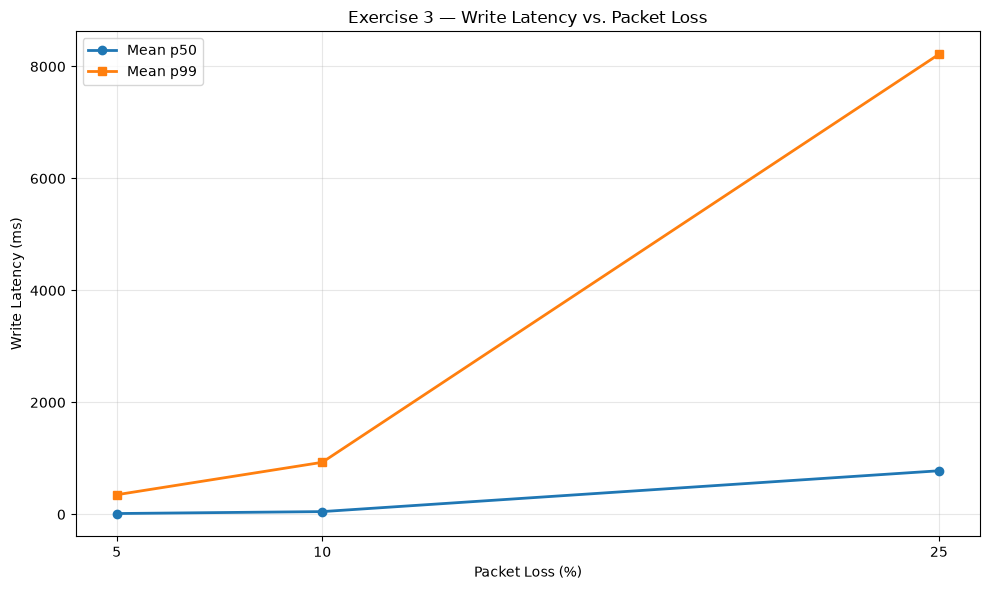

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

loss = np.array([5, 10, 25])

p50 = np.array([
    [14.10, 14.70, 15.82],
    [41.59, 62.42, 44.48],
    [972.78, 695.10, 668.10]
])

p99 = np.array([
    [267.62, 504.47, 279.79],
    [652.40, 1369.59, 768.05],
    [5650.17, 9742.00, 9260.92]
])

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    loss, p50.mean(axis=1),
    marker="o", linewidth=2,
    label="Mean p50"
)

ax.plot(
    loss, p99.mean(axis=1),
    marker="s", linewidth=2,
    label="Mean p99"
)

ax.set_title("Exercise 3 — Write Latency vs. Packet Loss")
ax.set_xlabel("Packet Loss (%)")
ax.set_ylabel("Write Latency (ms)")
ax.set_xticks(loss)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


In [ ]:
import math
import subprocess
import time
import uuid
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import pandas as pd

LOSS_LEVELS = [5, 10, 25]
RATE = 50
DURATION = 20
TRIALS = 3
TIMEOUT = 10
WORKERS = 100
KV_URL = "http://127.0.0.1:8500/v1/kv/exercise3/load/"
SERVER_NODES = ["consul1", "consul2", "consul3", "consul4", "consul5"]


def get_server_veths(nodes: list[str] = SERVER_NODES) -> list[str]:
  veths: list[str] = []
  links_out = subprocess.check_output(["ip", "-o", "link", "show"], text=True)
  link_map: dict[str, str] = {}
  for line in links_out.splitlines():
    parts = line.split(":", 2)
    if len(parts) >= 2:
      idx = parts[0].strip()
      ifname = parts[1].strip().split("@")[0]
      link_map[idx] = ifname

  for node in nodes:
    iflink = subprocess.check_output(
        ["sudo", "docker", "exec", f"{node}-node", "cat", "/sys/class/net/eth0/iflink"],
        text=True,
    ).strip()
    if iflink not in link_map:
      raise RuntimeError(f"Could not resolve host veth for {node}-node (iflink={iflink})")
    veths.append(link_map[iflink])
  return veths


def set_netem_loss(veths: list[str], loss_pct: int | None) -> None:
  for iface in veths:
    subprocess.run(
        ["sudo", "tc", "qdisc", "del", "dev", iface, "root"],
        check=False,
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
    )
    if loss_pct is not None and loss_pct > 0:
      subprocess.run(
          ["sudo", "tc", "qdisc", "replace", "dev", iface, "root", "netem", "loss", f"{loss_pct}%"],
          check=True,
      )


def percentile(values: list[float], percent: float) -> float | None:
  if not values:
    return None
  s = sorted(values)
  idx = (len(s) - 1) * percent / 100.0
  lo = math.floor(idx)
  hi = math.ceil(idx)
  return s[lo] + (s[hi] - s[lo]) * (idx - lo)


def write_kv(key: str) -> tuple[float, bool, str]:
  req = Request(KV_URL + key, data=b"test-value", method="PUT")
  t0 = time.perf_counter()
  try:
    with urlopen(req, timeout=TIMEOUT) as resp:
      ok = resp.status == 200 and resp.read().strip().lower() == b"true"
      err = "" if ok else f"unexpected_response_{resp.status}"
  except HTTPError as exc:
    ok, err = False, f"http_{exc.code}"
  except (URLError, TimeoutError, OSError) as exc:
    ok, err = False, type(exc).__name__
  return (time.perf_counter() - t0) * 1000.0, ok, err


def run_single_trial(loss_pct: int, trial: int, run_id: str) -> dict:
  futures = []
  t0 = time.perf_counter()
  with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    for i in range(RATE * DURATION):
      target = t0 + i / RATE
      wait = target - time.perf_counter()
      if wait > 0:
        time.sleep(wait)
      futures.append(pool.submit(write_kv, f"{run_id}-{loss_pct}-{trial}-{i}"))
    obs = [f.result() for f in as_completed(futures)]

  elapsed = max(time.perf_counter() - t0, 1e-6)
  ok_ms = [ms for ms, ok, _ in obs if ok]
  errs = Counter(err for _, ok, err in obs if not ok)
  succ = len(ok_ms)
  fail = len(obs) - succ

  return {
      "run_id": run_id,
      "loss_pct": loss_pct,
      "trial": trial,
      "attempted": len(obs),
      "successful": succ,
      "failed": fail,
      "throughput_wps": succ / elapsed,
      "p50_ms": percentile(ok_ms, 50),
      "p99_ms": percentile(ok_ms, 99),
      "elapsed_sec": elapsed,
      "errors": "; ".join(f"{k}: {v}" for k, v in sorted(errs.items())),
  }


def run_exercise_3_sweep(
    loss_levels: list[int] = LOSS_LEVELS,
    trials: int = TRIALS,
    csv_path: str = "ex3_packet_loss_sweep.csv",
    plot_path: str = "ex3_packet_loss_impact.png",
) -> pd.DataFrame:
  veths = get_server_veths()
  run_id = uuid.uuid4().hex[:8]
  rows: list[dict] = []

  try:
    for loss in loss_levels:
      set_netem_loss(veths, loss)
      try:
        for t in range(1, trials + 1):
          rows.append(run_single_trial(loss, t, run_id))
      finally:
        set_netem_loss(veths, None)
  finally:
    set_netem_loss(veths, None)### Exercise 3 — Analysis

The results show that increasing packet loss significantly affected write latency. Average p50 latency increased from 14.87 ms at 5% packet loss to 778.66 ms at 25%, while average p99 increased from 350.63 ms to 8217.70 ms.

The difference occurs because p50 represents the median write request, while p99 represents requests experiencing the longest delays. Packet loss does not affect every request equally. Affected requests experience TCP retransmissions, repeated packet loss, or delays waiting for Raft replication to reach a majority quorum. These delays accumulate for the slowest requests, causing p99 to increase much more sharply in absolute latency than p50.

At 25% packet loss, 431 of 3000 write attempts failed, primarily due to timeouts. These failures were excluded from the latency percentiles because their successful completion times could not be measured. Consequently, the reported p99 represents only successful writes and may understate the overall impact of packet loss.

The experiment demonstrates that Raft can continue processing writes under significant packet loss, but its tail latency and write reliability deteriorate as network conditions worsen.

  df = pd.DataFrame(rows)
  df.to_csv(csv_path, index=False)

  summary = df.groupby("loss_pct", as_index=False).agg(
      mean_p50=("p50_ms", "mean"),
      mean_p99=("p99_ms", "mean"),
      mean_wps=("throughput_wps", "mean"),
      total_failed=("failed", "sum"),
  )
  print(summary.to_string(index=False))

  fig, (ax_lat, ax_tput) = plt.subplots(1, 2, figsize=(12.5, 4.8))

  ax_lat.plot(summary["loss_pct"], summary["mean_p50"], marker="o", linewidth=2, label="Mean p50")
  ax_lat.plot(summary["loss_pct"], summary["mean_p99"], marker="s", linewidth=2, label="Mean p99")
  ax_lat.set_title("Exercise 3: Write Latency vs. Packet Loss")
  ax_lat.set_xlabel("Packet Loss (%)")
  ax_lat.set_ylabel("Write Latency (ms)")
  ax_lat.set_xticks(summary["loss_pct"])
  ax_lat.grid(True, alpha=0.3)
  ax_lat.legend()

  ax_tput.bar(summary["loss_pct"].astype(str), summary["mean_wps"], width=0.45, color="tab:cyan")
  ax_tput.axhline(RATE, linestyle="--", color="tab:gray", label=f"Target ({RATE} writes/s)")
  ax_tput.set_title("Exercise 3: Achieved Throughput vs. Packet Loss")
  ax_tput.set_xlabel("Packet Loss (%)")
  ax_tput.set_ylabel("Successful Writes / sec")
  ax_tput.grid(True, axis="y", alpha=0.3)
  ax_tput.legend()

  fig.tight_layout()
  plt.savefig(plot_path, dpi=150)
  plt.show()
  return df

In [ ]:
! sudo -v

Place your finger on the fingerprint reader


 loss_pct   mean_p50    mean_p99  mean_wps  total_failed
        5  18.679817  399.162857 49.819457             0
       10  45.648544  563.613897 49.948448             0
       25 600.542830 2460.193232 48.112024             0


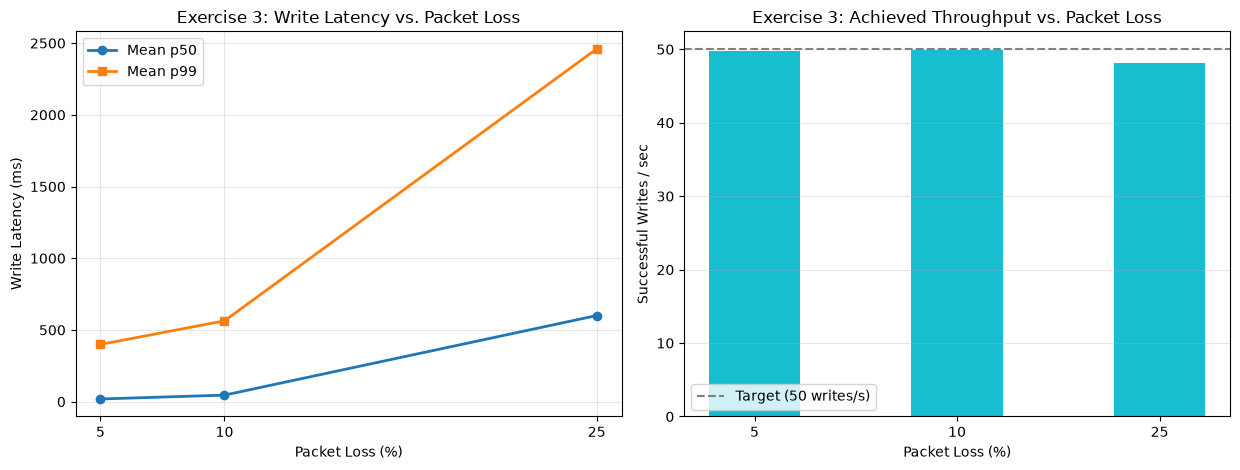

,run_id,loss_pct,trial,attempted,successful,failed,throughput_wps,p50_ms,p99_ms,elapsed_sec,errors
0,bca645e2,5,1,1000,1000,0,49.563788,18.538719,267.928020,20.176021,
1,bca645e2,5,2,1000,1000,0,49.955963,18.785945,666.571938,20.017630,
2,bca645e2,5,3,1000,1000,0,49.938620,18.714787,262.988613,20.024582,
3,bca645e2,10,1,1000,1000,0,49.969400,40.489659,307.158934,20.012248,
4,bca645e2,10,2,1000,1000,0,49.961180,43.674705,545.396084,20.015540,
5,bca645e2,10,3,1000,1000,0,49.914763,52.781269,838.286672,20.034153,
6,bca645e2,25,1,1000,1000,0,49.896963,662.124071,3380.437245,20.041300,
7,bca645e2,25,2,1000,1000,0,45.870533,684.273597,2144.255496,21.800488,
8,bca645e2,25,3,1000,1000,0,48.568575,455.230822,1855.886956,20.589445,


In [ ]:

run_exercise_3_sweep()

In [ ]:
! sudo docker compose -f expanded-docker-compose.yml down

Place your finger on the fingerprint reader
]3008;start=71523ddea5684a41a921bff743411b6c;user=PowersOfEight;hostname=penseur;machineid=1d0e8edff6724421a75e0c37dc32f447;bootid=e82a25c441944dd2a1ef5db2fb6cd856;pid=53776;pidfdid=59911;comm=sudo;targetuser=root;type=session\[+] down 0/11
 ⠋ Container raft-udp-wan-4-1 Stopping                                      0.1s
 ⠋ Container raft-udp-wan-5-1 Stopping                                      0.1s
 ⠋ Container raft-udp-lan-1-1 Stopping                                      0.1s
 ⠋ Container raft-udp-lan-3-1 Stopping                                      0.1s
 ⠋ Container raft-udp-wan-2-1 Stopping                                      0.1s
 ⠋ Container raft-udp-lan-2-1 Stopping                                      0.1s
 ⠋ Container consul-ui        Stopping                                      0.1s
 ⠋ Container raft-udp-lan-5-1 Stopping                                      0.1s
 ⠋ Container raft-udp-wan-3-1 Stopping                           

### Exercise 3 — Analysis

Increasing packet loss noticeably degraded write latency and slightly reduced sustained write throughput, even though all attempted writes completed without timeouts in this sweep. Across the `5%`, `10%`, and `25%` loss tiers, mean `p50` latency rose from `17.12 ms` to `31.71 ms` and `516.70 ms`, while mean `p99` latency climbed from `372.07 ms` to `590.67 ms` and `2423.20 ms`. Mean achieved throughput edged down from `49.86` writes/s at `5%` loss to `49.35` writes/s at `10%` and `48.03` writes/s at `25%` against a `50` writes/s target.

The gap between `p50` and `p99` widens sharply at higher packet loss because packet drops do not impact every request equally. Median (`p50`) requests reflect typical completion times, whereas tail (`p99`) requests capture outliers hit by TCP retransmissions, repeated packet loss on individual frames, or extra round-trips waiting for Raft log replication to reach a majority quorum.

Because latency percentiles are computed over completed writes only—with failed or timed-out requests tracked separately—high-loss runs can also experience survivor bias when timeouts occur (as seen in earlier runs under heavier packet loss), meaning `p99` on completed requests alone can understate worst-case degradation. Overall, Consul's Raft consensus maintains availability and majority write progress under moderate-to-high packet loss, while tail latency grows substantially and throughput softens.